In [7]:
import sys
from pathlib import Path
import cv2
import os
import json
from scipy.interpolate import RectBivariateSpline


# Add the WEBAT project root to Python path
project_root = Path("..").resolve()  # assumes notebook is in /examples folder
sys.path.insert(0, str(project_root))

# Now you can import webat modules
from webat.model.depth_analysis import *
from webat.utility.utils import *
import matplotlib.pyplot as plt
from load_stereo_maps import load_stereo_maps

In [2]:
VID_FOLDER = "../data"
LFT_VIDEO_PATH = os.path.join(VID_FOLDER, "Left 2023-07-06_21_50_13.mp4")
MID_VIDEO_PATH = os.path.join(VID_FOLDER, "Middle 2023-07-06_21_50_10.mp4")
RGT_VIDEO_PATH = os.path.join(VID_FOLDER, "Right 2023-07-06_21_50_00.mp4")

In [3]:
def vid_to_images(video_path, output_folder):
    cap = cv2.VideoCapture(video_path)
    frame_count = 0
    os.makedirs(output_folder, exist_ok=True)
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        if frame_count >= 100:
            break
        frame_filename = os.path.join(output_folder, f"frame_{frame_count:04d}.png")
        cv2.imwrite(frame_filename, frame)
        frame_count += 1
    cap.release()


# Collect frames from each video if not have done yet
# vid_to_images(LFT_VIDEO_PATH, LFT_VIDEO_PATH[:-4])
# vid_to_images(MID_VIDEO_PATH, MID_VIDEO_PATH[:-4])
# vid_to_images(RGT_VIDEO_PATH, RGT_VIDEO_PATH[:-4])

The stereoMap_validated.xml contains:

- map1 → X coordinates in the original image for each pixel in the rectified image
- map2 → Y coordinates in the original image for each pixel in the rectified image


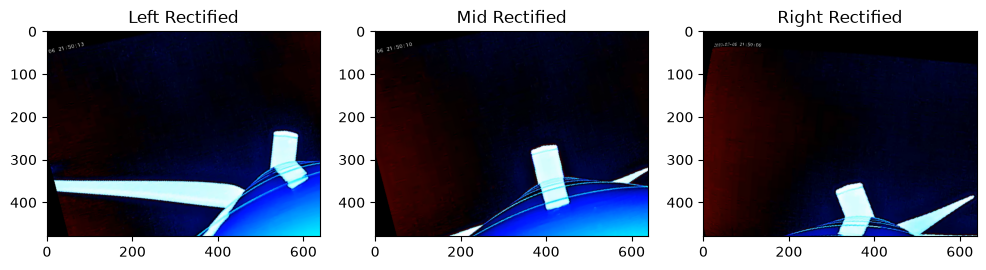

In [4]:
left_frame = cv2.imread(f"../data/{LFT_VIDEO_PATH[:-4]}/frame_0000.png")
mid_frame = cv2.imread(f"../data/{MID_VIDEO_PATH[:-4]}/frame_0000.png")
right_frame = cv2.imread(f"../data/{RGT_VIDEO_PATH[:-4]}/frame_0000.png")

# Automatically converts to correct type
map1_left, map2_left, map1_right, map2_right, Q = load_stereo_maps('../camera_calibration/stereoMap_validated.xml')

left_rect = cv2.remap(left_frame, map1_left, map2_left, cv2.INTER_LANCZOS4)
mid_rect = cv2.remap(mid_frame, map1_left, map2_left, cv2.INTER_LANCZOS4)
right_rect = cv2.remap(right_frame, map1_right, map2_right, cv2.INTER_LANCZOS4)

# View rectified frames
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(left_rect, cmap='gray')
plt.title('Left Rectified')
plt.subplot(1, 3, 2)
plt.imshow(mid_rect, cmap='gray')
plt.title('Mid Rectified')
plt.subplot(1, 3, 3)
plt.imshow(right_rect, cmap='gray')
plt.title('Right Rectified')
plt.show()


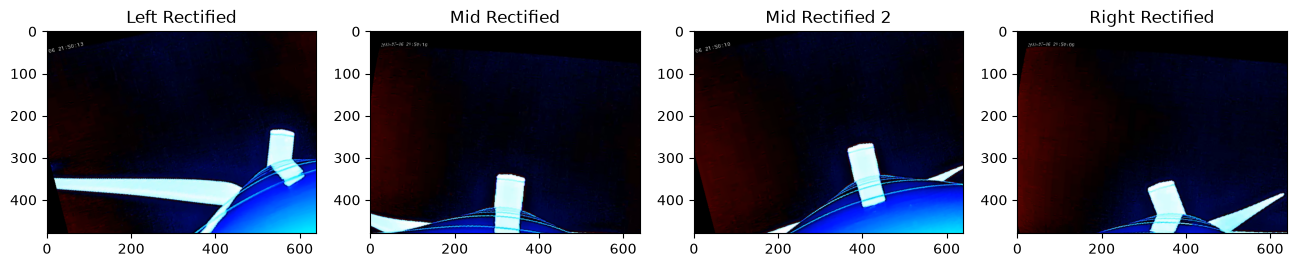

In [5]:
# Same XML file but using original calibration loading function from WEBAT

left_frame = cv2.imread(f"../data/{LFT_VIDEO_PATH[:-4]}/frame_0000.png")
mid_frame = cv2.imread(f"../data/{MID_VIDEO_PATH[:-4]}/frame_0000.png")
right_frame = cv2.imread(f"../data/{RGT_VIDEO_PATH[:-4]}/frame_0000.png")

# Read the stereo calibration matrix
stereoMap = read_calibration_matrix("../camera_calibration/stereoMap_validated.xml")
stereoMapL_x, stereoMapL_y, stereoMapR_x, stereoMapR_y, Q = stereoMap
left_rectified, mid_rectified1 = rectify_frames(left_frame, mid_frame, stereoMapL_x, stereoMapL_y, stereoMapR_x, stereoMapR_y)
mid_rectified2, right_rectified = rectify_frames(mid_frame, right_frame, stereoMapL_x, stereoMapL_y, stereoMapR_x, stereoMapR_y)

# View rectified frames
plt.figure(figsize=(16, 5))
plt.subplot(1, 4, 1)
plt.imshow(left_rectified, cmap='gray')
plt.title('Left Rectified')
plt.subplot(1, 4, 2)
plt.imshow(mid_rectified1, cmap='gray')
plt.title('Mid Rectified')
plt.subplot(1, 4, 3)
plt.imshow(mid_rectified2, cmap='gray')
plt.title('Mid Rectified 2')
plt.subplot(1, 4, 4)
plt.imshow(right_rectified, cmap='gray')
plt.title('Right Rectified')
plt.show()

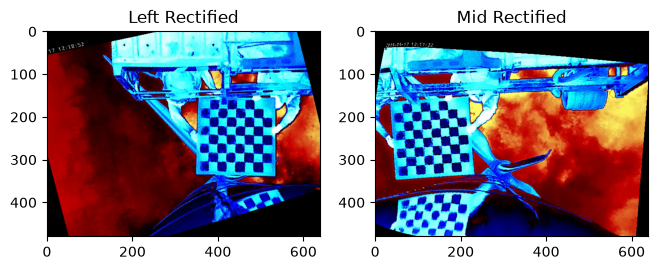

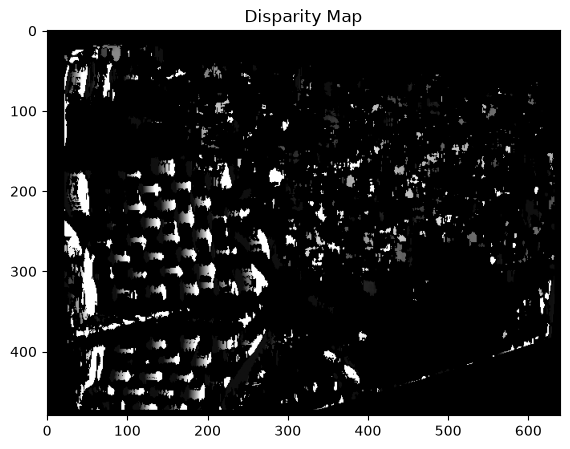

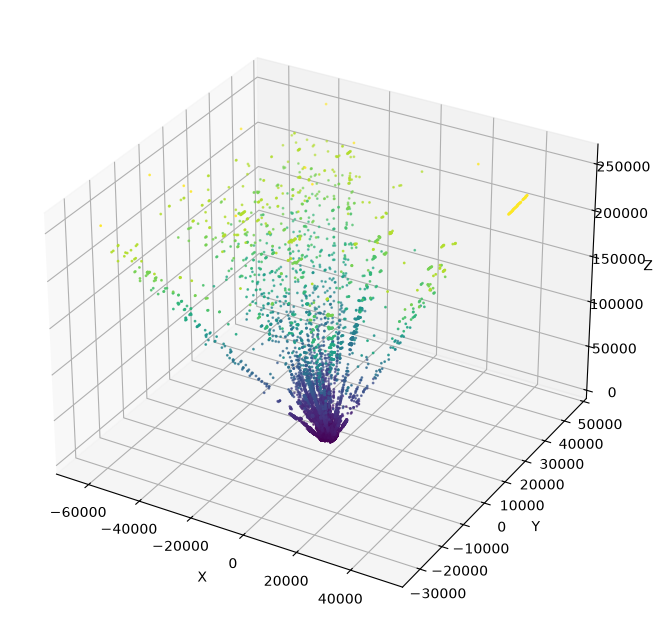

In [6]:
# Test with frames with checkerboards as we know true height

# 35529: Used for Corner Detection
# 
left_frame = cv2.imread(f"../camera_calibration/experiment_data/frames_pair/left_35529.png")
mid_frame = cv2.imread(f"../camera_calibration/experiment_data/frames_pair/middle_35529.png")

# Automatically converts to correct type
map1_left, map2_left, map1_right, map2_right, Q = load_stereo_maps('../camera_calibration/stereoMap_validated.xml')

left_rect = cv2.remap(left_frame, map1_left, map2_left, cv2.INTER_LANCZOS4)
mid_rect = cv2.remap(mid_frame, map1_right, map2_right, cv2.INTER_LANCZOS4)

# View rectified frames
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(left_rect, cmap='gray')
plt.title('Left Rectified')
plt.subplot(1, 3, 2)
plt.imshow(mid_rect, cmap='gray')
plt.title('Mid Rectified')
plt.show()

# Compute disparity map between left and mid rectified frames
gray_left = cv2.cvtColor(left_rect, cv2.COLOR_BGR2GRAY)
gray_mid = cv2.cvtColor(mid_rect, cv2.COLOR_BGR2GRAY)
stereo = cv2.StereoBM_create(numDisparities=16, blockSize=15)
disparity = stereo.compute(gray_left, gray_mid)
plt.figure(figsize=(12, 5))
plt.imshow(disparity, cmap='gray')
plt.title('Disparity Map')
plt.show()

# Estimate 3D surface from disparity map
points_3D = cv2.reprojectImageTo3D(disparity, Q)
out_points = points_3D[disparity > disparity.min()]             # Mask out invalid/infinite points
# Visualize 3D plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(out_points[:, 0], out_points[:, 1], out_points[:, 2], c=out_points[:, 2], cmap='viridis', s=1)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()



Original left [468.7606506347656, 373.352783203125] → Rectified left (505, 306)
Original right [230.85060119628906, 287.1715393066406] → Rectified right (200, 307)
607.6578147742032 cm -> 19.93628065023797 ft
Depth (Z): 6648.7298446601235 mm -> 21.81341882355472 ft
Original left [446.16302490234375, 368.1440124511719] → Rectified left (483, 307)
Original right [209.0107879638672, 291.51629638671875] → Rectified right (179, 308)
609.6566891649078 cm -> 20.001860520797962 ft
Depth (Z): 6670.600666517559 mm -> 21.88517349073747 ft
Original left [425.3780517578125, 361.50445556640625] → Rectified left (462, 306)
Original right [187.905517578125, 294.75885009765625] → Rectified right (159, 309)
611.6687574459801 cm -> 20.067873261790695 ft
Depth (Z): 6692.615850235438 mm -> 21.957401786086436 ft
Original left [403.9059753417969, 355.7141418457031] → Rectified left (441, 306)
Original right [165.6930694580078, 298.46551513671875] → Rectified right (138, 310)
611.6687574459801 cm -> 20.067873

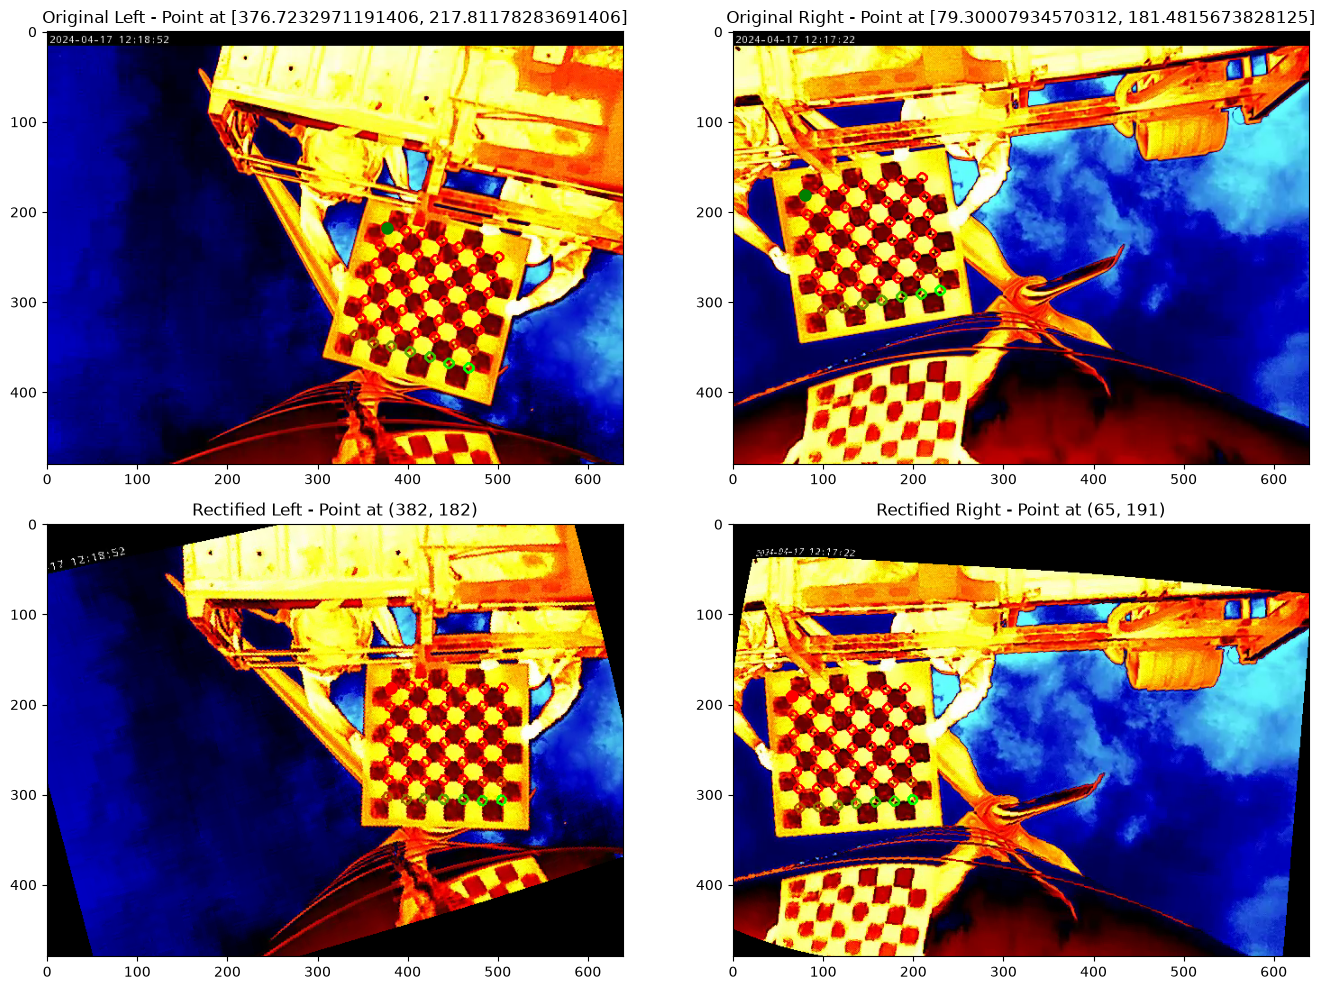

Original left [480.621337890625, 378.49700927734375] → Rectified left (517, 307)
Original right [231.39736938476562, 283.8017272949219] → Rectified right (201, 303)
586.5051693232024 cm -> 19.242296197223354 ft
Depth (Z): 6417.286717156132 mm -> 21.054090953114525 ft
Original left [457.8101501464844, 375.0211181640625] → Rectified left (496, 310)
Original right [209.7803497314453, 288.5638732910156] → Rectified right (180, 305)
586.5051693232024 cm -> 19.242296197223354 ft
Depth (Z): 6417.286717156132 mm -> 21.054090953114525 ft
Original left [436.22845458984375, 370.4742736816406] → Rectified left (474, 311)
Original right [189.376708984375, 291.8160095214844] → Rectified right (160, 306)
590.2408710386369 cm -> 19.364858593384017 ft
Depth (Z): 6458.161154845025 mm -> 21.188193443261753 ft
Original left [413.93450927734375, 366.49896240234375] → Rectified left (453, 313)
Original right [167.46710205078125, 295.6766662597656] → Rectified right (139, 308)
590.2408710386369 cm -> 19.3648

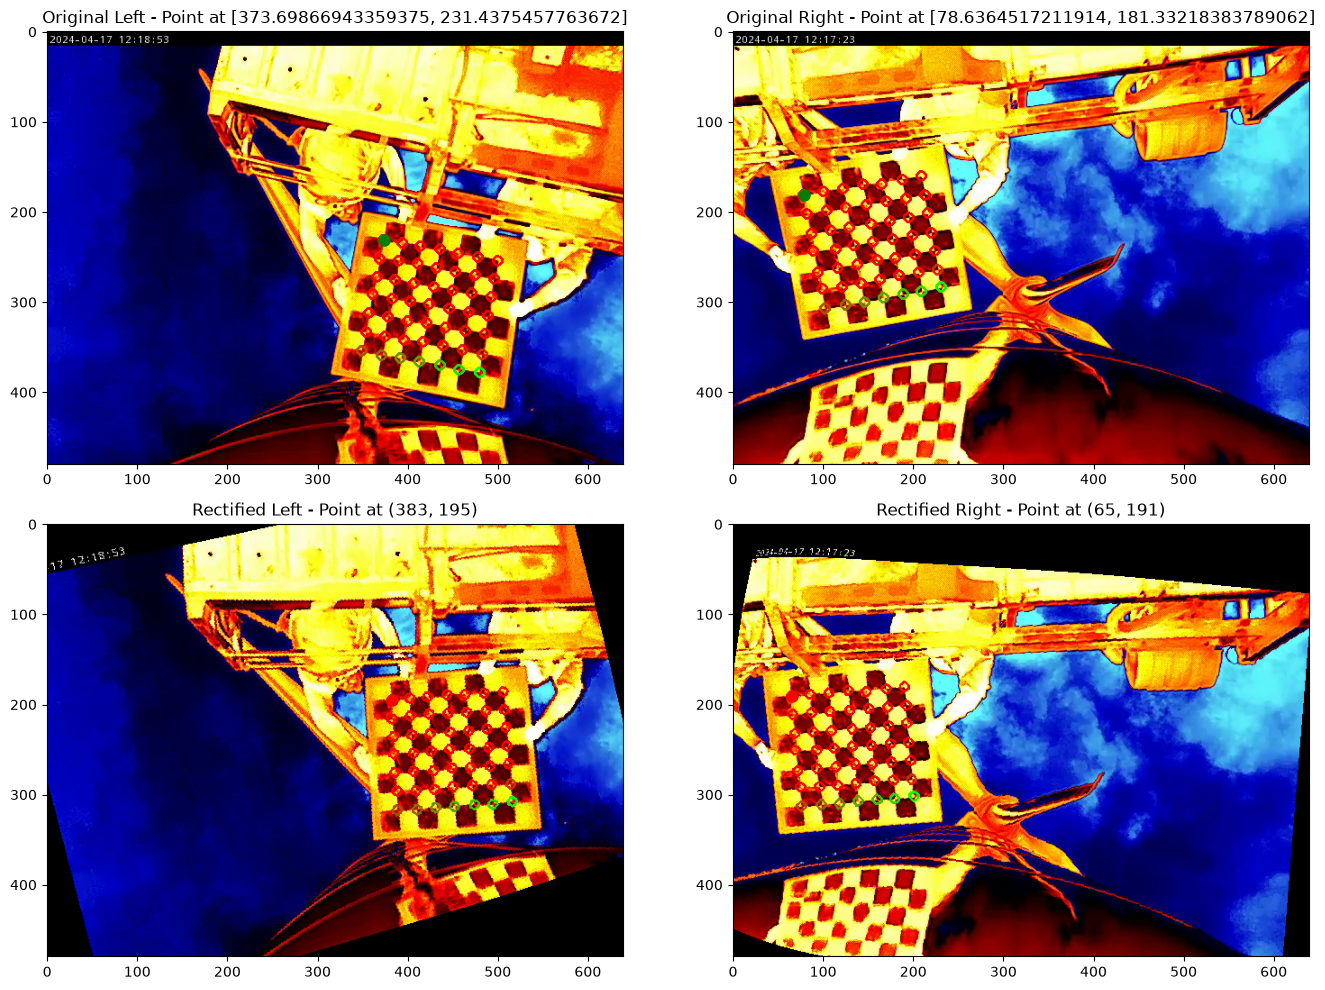

Original left [477.8534851074219, 370.6052551269531] → Rectified left (513, 302)
Original right [230.08055114746094, 286.51007080078125] → Rectified right (200, 306)
592.1266246202299 cm -> 19.426727151190352 ft
Depth (Z): 6478.794257576159 mm -> 21.255887352026168 ft
Original left [455.84326171875, 368.2315673828125] → Rectified left (492, 304)
Original right [208.42562866210938, 290.9278259277344] → Rectified right (178, 307)
590.2408710386369 cm -> 19.364858593384017 ft
Depth (Z): 6458.161154845025 mm -> 21.188193443261753 ft
Original left [435.925537109375, 364.0393371582031] → Rectified left (473, 305)
Original right [187.3575439453125, 293.75177001953125] → Rectified right (158, 308)
588.3670904956571 cm -> 19.303382851817716 ft
Depth (Z): 6437.659055940754 mm -> 21.120929337092665 ft
Original left [414.43609619140625, 360.5838317871094] → Rectified left (452, 308)
Original right [164.65774536132812, 297.63336181640625] → Rectified right (137, 310)
588.3670904956571 cm -> 19.3033

KeyboardInterrupt: 

In [10]:
# Get corners from validation_report.json file

def find_rectified_point(original_point, map1, map2):
    """
    Find where a point in original image maps to in rectified image.
    Uses interpolation to handle sub-pixel coordinates.
    
    Args:
        original_point: (x, y) in original image
        map1, map2: Rectification maps
    
    Returns:
        (rect_x, rect_y) in rectified image, or None if outside bounds
    """
    orig_x, orig_y = original_point
    h, w = map1.shape
    
    # Create interpolation functions for both maps
    # These let us query the maps at any pixel location
    x_coords = np.arange(w)
    y_coords = np.arange(h)
    
    spline_map1 = RectBivariateSpline(y_coords, x_coords, map1, kx=1, ky=1)
    spline_map2 = RectBivariateSpline(y_coords, x_coords, map2, kx=1, ky=1)
    
    # Now we need to solve: find (rect_x, rect_y) such that
    # map1[rect_y, rect_x] ≈ orig_x AND map2[rect_y, rect_x] ≈ orig_y
    
    # Method: Try all pixels and find the closest match
    min_distance = float('inf')
    best_point = None
    
    for rect_y in range(h):
        for rect_x in range(w):
            mapped_x = map1[rect_y, rect_x]
            mapped_y = map2[rect_y, rect_x]
            
            # Calculate distance from original point
            distance = np.sqrt((mapped_x - orig_x)**2 + (mapped_y - orig_y)**2)
            
            if distance < min_distance:
                min_distance = distance
                best_point = (rect_x, rect_y)
    
    # Only return if we found a reasonable match (within 1 pixel)
    if min_distance < 1.0 and best_point is not None:
        return best_point, min_distance
    else:
        return None, min_distance

def find_depth_new(point_rect_left, point_rect_right, Q):
    """
    Calculate 3D depth from rectified stereo pair using disparity.
    
    Args:
        point_rect_left: (x, y) in left rectified image
        point_rect_right: (x, y) in right rectified image
        Q: Reprojection matrix from stereoMap
    
    Returns:
        (X, Y, Z) in 3D space
    """
    x_left, y_left = point_rect_left
    x_right, y_right = point_rect_right
    
    # Disparity is the difference in X coordinates
    disparity = x_left - x_right
    
    if disparity == 0:
        return None
    
    # Create homogeneous coordinates for reprojection
    # Format: [x, y, disparity, 1]
    homogeneous = np.array([x_left, y_left, disparity, 1.0])
    
    # Apply Q matrix to get 3D point
    point_3d = Q @ homogeneous
    
    # Normalize by the 4th coordinate
    X = point_3d[0] / point_3d[3]
    Y = point_3d[1] / point_3d[3]
    Z = point_3d[2] / point_3d[3]
    
    # print(f"3D Point: ({X:.2f}, {Y:.2f}, {Z:.2f})")
    return (X, Y, Z)

# Load stereo maps and Q matrix for 3D reconstruction
map1_left, map2_left, map1_right, map2_right, Q = load_stereo_maps('../camera_calibration/stereoMap_validated.xml')

with open('../camera_calibration/experiment_data/validated_corners/validation_report.json', 'r') as f:
    validation_report = json.load(f)

pairs = validation_report['validated_pairs']
for p in pairs:
    left_original = cv2.imread(f"../camera_calibration/experiment_data/frames_pair/{p['left_file']}")
    right_original = cv2.imread(f"../camera_calibration/experiment_data/frames_pair/{p['right_file']}")
    point_org_lefts = p["left_corners"]
    point_org_rights = p["right_corners"]
    assert len(point_org_lefts) == len(point_org_rights)  # 7x7 grid

    # There is 7x7 grid of corners
    for idx in range(len(point_org_lefts)):
        point_org_left = point_org_lefts[idx][0]
        point_org_right = point_org_rights[idx][0]

        # Find where they map to in RECTIFIED images
        point_rect_left, _ = find_rectified_point(point_org_left, map1_left, map2_left)
        point_rect_right, _ = find_rectified_point(point_org_right, map1_right, map2_right)

        print(f"Original left {point_org_left} → Rectified left {point_rect_left}")
        print(f"Original right {point_org_right} → Rectified right {point_rect_right}")

        # Visualize
        left_rect = cv2.remap(left_original, map1_left, map2_left, cv2.INTER_LANCZOS4)
        right_rect = cv2.remap(right_original, map1_right, map2_right, cv2.INTER_LANCZOS4)

        # Draw circles on all images
        # Color by idx
        color = (0, 255 - idx * 30, idx * 30)  # Example color variation by idx
        cv2.circle(left_original, tuple(map(int, point_org_left)), 5, color, 2)
        cv2.circle(right_original, tuple(map(int, point_org_right)), 5, color, 2)

        if point_rect_left:
            cv2.circle(left_rect, tuple(map(int, point_rect_left)), 5, color, 2)
        if point_rect_right:
            cv2.circle(right_rect, tuple(map(int, point_rect_right)), 5, color, 2)

        depth = find_depth(point_rect_left, point_rect_right)
        print(f"{depth} cm -> {depth * 0.0328084} ft")

        point_3d = find_depth_new(point_rect_left, point_rect_right, Q)
        # print(f"3D Point: {point_3d}")
        print(f"Depth (Z): {point_3d[2]} mm -> {point_3d[2] * 0.00328084} ft")


    # Display
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    axes[0, 0].imshow(cv2.cvtColor(left_original, cv2.COLOR_BGR2RGB))
    axes[0, 0].set_title(f'Original Left - Point at {point_org_left}')
    axes[0, 0].plot(*point_org_left, 'go', markersize=8)

    axes[0, 1].imshow(cv2.cvtColor(right_original, cv2.COLOR_BGR2RGB))
    axes[0, 1].set_title(f'Original Right - Point at {point_org_right}')
    axes[0, 1].plot(*point_org_right, 'go', markersize=8)

    axes[1, 0].imshow(cv2.cvtColor(left_rect, cv2.COLOR_BGR2RGB))
    axes[1, 0].set_title(f'Rectified Left - Point at {point_rect_left}')
    if point_rect_left:
        axes[1, 0].plot(*point_rect_left, 'ro', markersize=8)

    axes[1, 1].imshow(cv2.cvtColor(right_rect, cv2.COLOR_BGR2RGB))
    axes[1, 1].set_title(f'Rectified Right - Point at {point_rect_right}')
    if point_rect_right:
        axes[1, 1].plot(*point_rect_right, 'ro', markersize=8)

    plt.tight_layout()
    plt.show()

        



Original left (468.7606506347656, 373.352783203125) → Rectified left (505, 306)
Original right (230.85060119628906, 287.1715393066406) → Rectified right (200, 307)


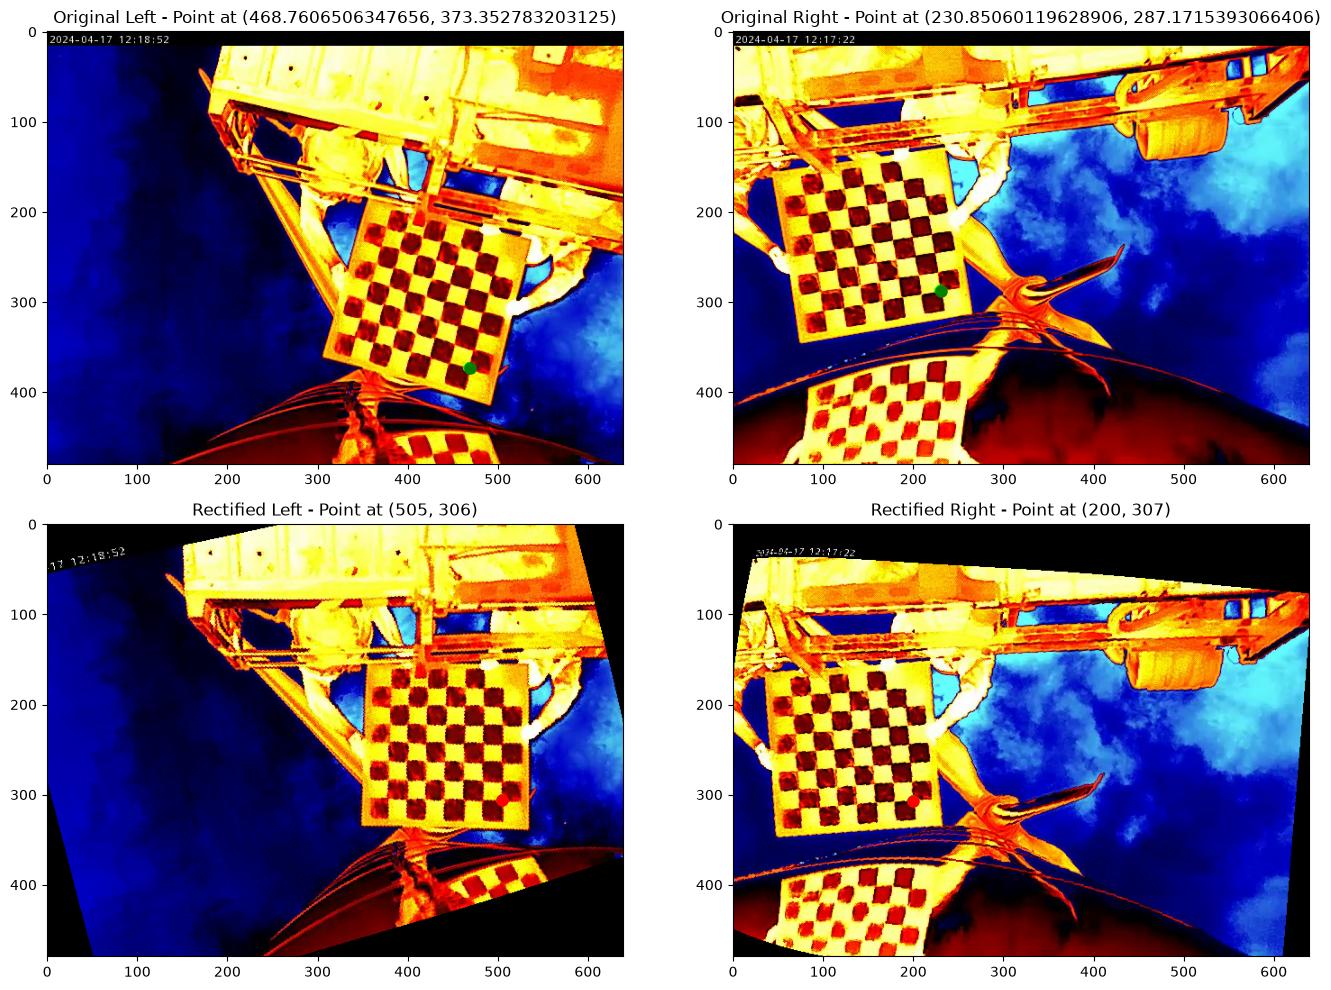

607.6578147742032 cm
Left X:  505
Right X: 200
Disparity: 305 pixels
3D Point: (695.53, 384.64, 6648.73)
3D Point: (np.float64(695.5305321683887), np.float64(384.64043047792205), np.float64(6648.7298446601235))
Depth (Z): 6648.7298446601235 mm


In [ ]:
# Compute D-depth from specific points from WEBAT function

from scipy.interpolate import RectBivariateSpline

def find_rectified_point(original_point, map1, map2):
    """
    Find where a point in original image maps to in rectified image.
    Uses interpolation to handle sub-pixel coordinates.
    
    Args:
        original_point: (x, y) in original image
        map1, map2: Rectification maps
    
    Returns:
        (rect_x, rect_y) in rectified image, or None if outside bounds
    """
    orig_x, orig_y = original_point
    h, w = map1.shape
    
    # Create interpolation functions for both maps
    # These let us query the maps at any pixel location
    x_coords = np.arange(w)
    y_coords = np.arange(h)
    
    spline_map1 = RectBivariateSpline(y_coords, x_coords, map1, kx=1, ky=1)
    spline_map2 = RectBivariateSpline(y_coords, x_coords, map2, kx=1, ky=1)
    
    # Now we need to solve: find (rect_x, rect_y) such that
    # map1[rect_y, rect_x] ≈ orig_x AND map2[rect_y, rect_x] ≈ orig_y
    
    # Method: Try all pixels and find the closest match
    min_distance = float('inf')
    best_point = None
    
    for rect_y in range(h):
        for rect_x in range(w):
            mapped_x = map1[rect_y, rect_x]
            mapped_y = map2[rect_y, rect_x]
            
            # Calculate distance from original point
            distance = np.sqrt((mapped_x - orig_x)**2 + (mapped_y - orig_y)**2)
            
            if distance < min_distance:
                min_distance = distance
                best_point = (rect_x, rect_y)
    
    # Only return if we found a reasonable match (within 1 pixel)
    if min_distance < 1.0 and best_point is not None:
        return best_point, min_distance
    else:
        return None, min_distance

def find_depth_new(point_rect_left, point_rect_right, Q):
    """
    Calculate 3D depth from rectified stereo pair using disparity.
    
    Args:
        point_rect_left: (x, y) in left rectified image
        point_rect_right: (x, y) in right rectified image
        Q: Reprojection matrix from stereoMap
    
    Returns:
        (X, Y, Z) in 3D space
    """
    x_left, y_left = point_rect_left
    x_right, y_right = point_rect_right
    
    # Disparity is the difference in X coordinates
    disparity = x_left - x_right
    
    print(f"Left X:  {x_left}")
    print(f"Right X: {x_right}")
    print(f"Disparity: {disparity} pixels")
    
    if disparity == 0:
        print("⚠️  No disparity - points are at same X (infinite depth)")
        return None
    
    # Create homogeneous coordinates for reprojection
    # Format: [x, y, disparity, 1]
    homogeneous = np.array([x_left, y_left, disparity, 1.0])
    
    # Apply Q matrix to get 3D point
    point_3d = Q @ homogeneous
    
    # Normalize by the 4th coordinate
    X = point_3d[0] / point_3d[3]
    Y = point_3d[1] / point_3d[3]
    Z = point_3d[2] / point_3d[3]
    
    print(f"3D Point: ({X:.2f}, {Y:.2f}, {Z:.2f})")
    return (X, Y, Z)

# 1: 35529 (32-38ft) 
#   -> webat.find_depth() results 607.65 cm = 19.93 ft
#   -> find_depth_new() results 6648.729 mm = 21.81 ft

# Sample corner points (x,y) I want to compute depth for
point_org_left = (468.7606506347656,
            373.352783203125)
point_org_right = (230.85060119628906,
            287.1715393066406)

# Rectify the points from stereo maps
map1_left, map2_left, map1_right, map2_right, Q = load_stereo_maps('../camera_calibration/stereoMap_validated.xml')

# Find where they map to in RECTIFIED images
point_rect_left, _ = find_rectified_point(point_org_left, map1_left, map2_left)
point_rect_right, _ = find_rectified_point(point_org_right, map1_right, map2_right)

print(f"Original left {point_org_left} → Rectified left {point_rect_left}")
print(f"Original right {point_org_right} → Rectified right {point_rect_right}")

# Visualize
left_original = cv2.imread("../camera_calibration/experiment_data/frames_pair/left_35529.png")
right_original = cv2.imread("../camera_calibration/experiment_data/frames_pair/middle_35529.png")

left_rect = cv2.remap(left_original, map1_left, map2_left, cv2.INTER_LANCZOS4)
right_rect = cv2.remap(right_original, map1_right, map2_right, cv2.INTER_LANCZOS4)

# Draw circles on all images
cv2.circle(left_original, tuple(map(int, point_org_left)), 5, (0, 255, 0), 2)
cv2.circle(right_original, tuple(map(int, point_org_right)), 5, (0, 255, 0), 2)

if point_rect_left:
    cv2.circle(left_rect, tuple(map(int, point_rect_left)), 5, (0, 255, 0), 2)
if point_rect_right:
    cv2.circle(right_rect, tuple(map(int, point_rect_right)), 5, (0, 255, 0), 2)

# Display
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].imshow(cv2.cvtColor(left_original, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title(f'Original Left - Point at {point_org_left}')
axes[0, 0].plot(*point_org_left, 'go', markersize=8)

axes[0, 1].imshow(cv2.cvtColor(right_original, cv2.COLOR_BGR2RGB))
axes[0, 1].set_title(f'Original Right - Point at {point_org_right}')
axes[0, 1].plot(*point_org_right, 'go', markersize=8)

axes[1, 0].imshow(cv2.cvtColor(left_rect, cv2.COLOR_BGR2RGB))
axes[1, 0].set_title(f'Rectified Left - Point at {point_rect_left}')
if point_rect_left:
    axes[1, 0].plot(*point_rect_left, 'ro', markersize=8)

axes[1, 1].imshow(cv2.cvtColor(right_rect, cv2.COLOR_BGR2RGB))
axes[1, 1].set_title(f'Rectified Right - Point at {point_rect_right}')
if point_rect_right:
    axes[1, 1].plot(*point_rect_right, 'ro', markersize=8)

plt.tight_layout()
plt.show()

depth = find_depth(point_rect_left, point_rect_right)
print(f"{depth} cm")

point_3d = find_depth_new(point_rect_left, point_rect_right, Q)
print(f"3D Point: {point_3d}")
print(f"Depth (Z): {point_3d[2]} mm")
